# **Q-Learning & SARSA**


In [2]:
!pip install gymnasium

In [3]:
import gymnasium as gym
import numpy as np
import random
import time
import matplotlib.pyplot as plt

In [4]:
from IPython import display
from gymnasium.envs.toy_text.frozen_lake import FrozenLakeEnv
from gymnasium.envs.toy_text.taxi import TaxiEnv

In [5]:
def q_learning(env, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate):
    q_table = np.zeros((env.observation_space.n, env.action_space.n))
    rewards_all = []
    for episode in range(num_episodes):
        state, _ = env.reset()

        reward_episode = 0.0
        done = False
        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-epsilon_decay_rate*episode)
        for step in range(num_steps_per_episode):
            exploration = random.uniform(0,1)
            if exploration < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(q_table[state, :])

            next_state, reward, terminated, truncated, _ = env.step(action)
            q_table[state, action] = q_table[state, action] * (1 - learning_rate) + learning_rate * (reward + gamma * np.max(q_table[next_state,:]))

            reward_episode += reward
            state = next_state

            if terminated or truncated:
                done = True

            if done:
                break
        rewards_all.append(reward_episode)
    print(f'Episode {episode} finished')
    return q_table, rewards_all

In [6]:
def sarsa(env, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate):
    q_table = np.zeros((env.observation_space.n, env.action_space.n))
    rewards_all = []

    for episode in range(num_episodes):
        reward_episode = 0.0
        done = False
        state, _ = env.reset()
        epsilon = min_epsilon +(max_epsilon - min_epsilon) * np.exp(-epsilon_decay_rate*episode)
        exploration = random.uniform(0,1)
        if exploration < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state, :])

        for step in range(num_steps_per_episode):
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            exploration = random.uniform(0,1)
            if exploration < epsilon:
                next_action = env.action_space.sample()
            else:
                next_action = np.argmax(q_table[next_state, :])
            sample = reward + gamma * q_table[next_state,next_action]
            q_table[state, action] = (1 - learning_rate)*q_table[state, action] + learning_rate * sample
            state = next_state
            action = next_action
            reward_episode += reward
            if done:
                break
        rewards_all.append(reward_episode)
        print(f'Episode {episode} finished')
    return q_table, rewards_all

In [7]:
def play(env, q_table, render=False):
    state, _ = env.reset()
    total_reward = 0
    steps = 0
    done = False

    if render:
        plt.axis('off')

    while not done:
        action = np.argmax(q_table[state, :])
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        total_reward += reward
        steps += 1
        if render:
            print(f"{state} --> {next_state}")
            time.sleep(0.5)
            screen = env.render()
            plt.imshow(screen)
            time.sleep(0.5)

        state = next_state

    return (total_reward, steps)

In [8]:
def play_multiple_times(env, q_table, max_episodes):
    success = 0
    list_of_steps = []
    for i in range(max_episodes):
        total_reward, steps = play(env, q_table)

        if total_reward > 0:
            success += 1
            list_of_steps.append(steps)

    print(f'Number of successes: {success}/{max_episodes}')
    print(f'Average number of steps: {np.mean(list_of_steps)}')

## FrozenLake

In [9]:
env = FrozenLakeEnv(desc=None, map_name="4x4", render_mode="ansi", is_slippery=True)

In [10]:
# Initialize Q-value table randomly
q_table = np.zeros((env.observation_space.n, env.action_space.n))
print(q_table)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [11]:
# Hyperparameters
gamma = 0.99
learning_rate = 0.1
max_epsilon = 1.0
min_epsilon = 0.01
epsilon_decay_rate = 0.005

num_episodes = 20000
num_steps_per_episode = 100

### Q_Learning


In [23]:
q_table, rewards_all = q_learning(env, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate)

Episode 79999 finished


In [24]:
start=time.time()
play_multiple_times(env, q_table, 1000)
end = time.time() - start
print("Time:", end)

Number of successes: 838/1000
Average number of steps: 44.65751789976134
Time: 0.4590883255004883


### SARSA

In [25]:
q_table_sarsa, rewards_all_sarsa = sarsa(env, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate)

Episode 0 finished
Episode 1 finished
Episode 2 finished
Episode 3 finished
Episode 4 finished
Episode 5 finished
Episode 6 finished
Episode 7 finished
Episode 8 finished
Episode 9 finished
Episode 10 finished
Episode 11 finished
Episode 12 finished
Episode 13 finished
Episode 14 finished
Episode 15 finished
Episode 16 finished
Episode 17 finished
Episode 18 finished
Episode 19 finished
Episode 20 finished
Episode 21 finished
Episode 22 finished
Episode 23 finished
Episode 24 finished
Episode 25 finished
Episode 26 finished
Episode 27 finished
Episode 28 finished
Episode 29 finished
Episode 30 finished
Episode 31 finished
Episode 32 finished
Episode 33 finished
Episode 34 finished
Episode 35 finished
Episode 36 finished
Episode 37 finished
Episode 38 finished
Episode 39 finished
Episode 40 finished
Episode 41 finished
Episode 42 finished
Episode 43 finished
Episode 44 finished
Episode 45 finished
Episode 46 finished
Episode 47 finished
Episode 48 finished
Episode 49 finished
Episode 50

In [26]:
start=time.time()
play_multiple_times(env, q_table_sarsa, 1000)
end = time.time() - start
print("Time:", end)

Number of successes: 795/1000
Average number of steps: 42.95849056603774
Time: 0.44795680046081543


In [27]:
window = 100
average_y = []
for ind in range(len(rewards_all) - window + 1):
    average_y.append(np.mean(rewards_all[ind:ind+window]))

for ind in range(window - 1):
    average_y.insert(0, np.nan)

In [28]:
window = 100
average_y_sarsa = []
for ind in range(len(rewards_all_sarsa) - window + 1):
    average_y_sarsa.append(np.mean(rewards_all_sarsa[ind:ind+window]))

for ind in range(window - 1):
    average_y_sarsa.insert(0, np.nan)

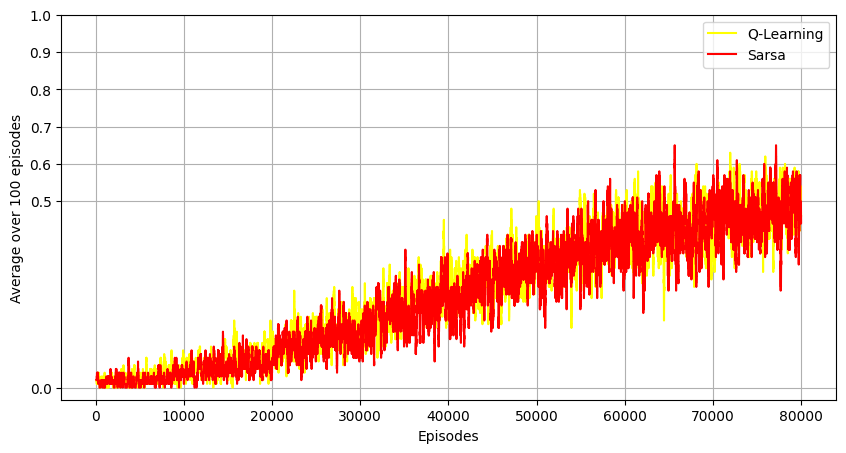

In [29]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(len(rewards_all)), average_y, color='yellow', label='Q-Learning')
plt.plot(np.arange(len(rewards_all_sarsa)), average_y_sarsa, color='red', label='Sarsa')
plt.yticks([0, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
plt.grid()
plt.xlabel('Episodes')
plt.ylabel(f'Average over {window} episodes')
plt.legend()
plt.show()

# **FrozenLake8x8-v1**

In [30]:
env2 = FrozenLakeEnv(desc=None, map_name="8x8", render_mode="ansi", is_slippery=True)

In [31]:

q_table = np.zeros((env.observation_space.n, env.action_space.n))
print(q_table)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [32]:
gamma = 0.99             
learning_rate = 0.1        
max_epsilon = 1.0          
min_epsilon = 0.05         # Giới hạn thấp hơn để vẫn còn một chút ngẫu nhiên
epsilon_decay_rate = 0.00005  # Giảm rất chậm, để khám phá lâu hơn
num_episodes = 80000       # Tăng số episode so với cấu hình gốc
num_steps_per_episode = 200  # Tăng lên 200

### Q_LEARNING

In [33]:
q_table, rewards_all = q_learning(env2, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate)

Episode 79999 finished


In [34]:
start=time.time()
play_multiple_times(env2, q_table, 1000)
end = time.time() - start
print("Time:", end)

Number of successes: 910/1000
Average number of steps: 93.99010989010989
Time: 0.8903172016143799


### SARSA

In [35]:
q_table_sarsa, rewards_all_sarsa = sarsa(env2, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate)

Episode 0 finished
Episode 1 finished
Episode 2 finished
Episode 3 finished
Episode 4 finished
Episode 5 finished
Episode 6 finished
Episode 7 finished
Episode 8 finished
Episode 9 finished
Episode 10 finished
Episode 11 finished
Episode 12 finished
Episode 13 finished
Episode 14 finished
Episode 15 finished
Episode 16 finished
Episode 17 finished
Episode 18 finished
Episode 19 finished
Episode 20 finished
Episode 21 finished
Episode 22 finished
Episode 23 finished
Episode 24 finished
Episode 25 finished
Episode 26 finished
Episode 27 finished
Episode 28 finished
Episode 29 finished
Episode 30 finished
Episode 31 finished
Episode 32 finished
Episode 33 finished
Episode 34 finished
Episode 35 finished
Episode 36 finished
Episode 37 finished
Episode 38 finished
Episode 39 finished
Episode 40 finished
Episode 41 finished
Episode 42 finished
Episode 43 finished
Episode 44 finished
Episode 45 finished
Episode 46 finished
Episode 47 finished
Episode 48 finished
Episode 49 finished
Episode 50

In [36]:
start=time.time()
play_multiple_times(env2, q_table_sarsa, 1000)
end = time.time() - start
print("Time:", end)


Number of successes: 919/1000
Average number of steps: 95.92709466811752
Time: 0.8709654808044434


In [37]:
window = 100
average_y = []
for ind in range(len(rewards_all) - window + 1):
    average_y.append(np.mean(rewards_all[ind:ind+window]))

for ind in range(window - 1):
    average_y.insert(0, np.nan)

In [38]:
window = 100
average_y_sarsa = []
for ind in range(len(rewards_all_sarsa) - window + 1):
    average_y_sarsa.append(np.mean(rewards_all_sarsa[ind:ind+window]))

for ind in range(window - 1):
    average_y_sarsa.insert(0, np.nan)

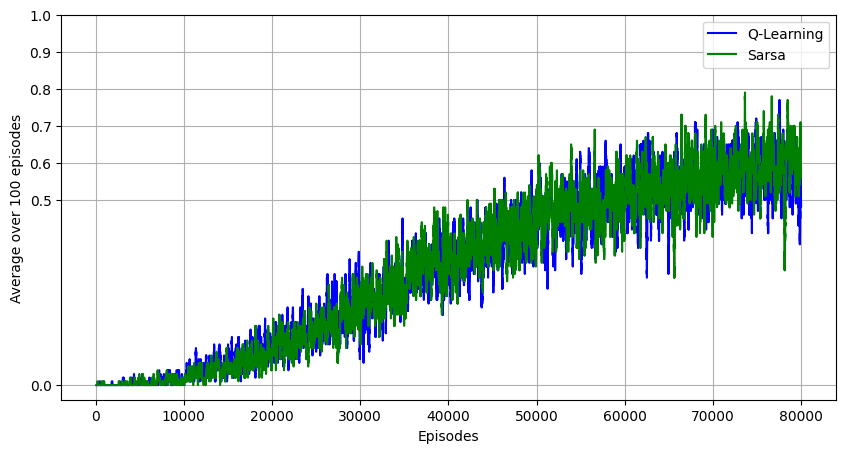

In [39]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(len(rewards_all)), average_y, color='blue', label='Q-Learning')
plt.plot(np.arange(len(rewards_all_sarsa)), average_y_sarsa, color='green', label='Sarsa')
plt.yticks([0, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
plt.grid()
plt.xlabel('Episodes')
plt.ylabel(f'Average over {window} episodes')
plt.legend()
plt.show()

# **Taxi-v3**

In [40]:
env3 = TaxiEnv()

In [41]:
# Hyperparameters
gamma = 0.99
learning_rate = 0.1
max_epsilon = 1.0
min_epsilon = 0.01
epsilon_decay_rate = 0.005

num_episodes = 20000
num_steps_per_episode = 100


### Q_LEARNING

In [42]:

q_table, rewards_all = q_learning(env3, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate)


Episode 19999 finished


In [43]:
start=time.time()
play_multiple_times(env3, q_table, 1000)
end = time.time() - start
print("Time:", end)

Number of successes: 1000/1000
Average number of steps: 13.085
Time: 0.21072888374328613


### SARSA

In [44]:
q_table_sarsa, rewards_all_sarsa = sarsa(env3, num_episodes, num_steps_per_episode, learning_rate, gamma, max_epsilon, min_epsilon, epsilon_decay_rate)

Episode 0 finished
Episode 1 finished
Episode 2 finished
Episode 3 finished
Episode 4 finished
Episode 5 finished
Episode 6 finished
Episode 7 finished
Episode 8 finished
Episode 9 finished
Episode 10 finished
Episode 11 finished
Episode 12 finished
Episode 13 finished
Episode 14 finished
Episode 15 finished
Episode 16 finished
Episode 17 finished
Episode 18 finished
Episode 19 finished
Episode 20 finished
Episode 21 finished
Episode 22 finished
Episode 23 finished
Episode 24 finished
Episode 25 finished
Episode 26 finished
Episode 27 finished
Episode 28 finished
Episode 29 finished
Episode 30 finished
Episode 31 finished
Episode 32 finished
Episode 33 finished
Episode 34 finished
Episode 35 finished
Episode 36 finished
Episode 37 finished
Episode 38 finished
Episode 39 finished
Episode 40 finished
Episode 41 finished
Episode 42 finished
Episode 43 finished
Episode 44 finished
Episode 45 finished
Episode 46 finished
Episode 47 finished
Episode 48 finished
Episode 49 finished
Episode 50

In [45]:
start=time.time()
play_multiple_times(env3, q_table_sarsa, 1000)
end = time.time() - start
print("Time:", end)

Number of successes: 1000/1000
Average number of steps: 12.995
Time: 0.4514920711517334


In [46]:
window = 100
average_y = []
for ind in range(len(rewards_all) - window + 1):
    average_y.append(np.mean(rewards_all[ind:ind+window]))

for ind in range(window - 1):
    average_y.insert(0, np.nan)

In [47]:
window = 100
average_y_sarsa = []
for ind in range(len(rewards_all_sarsa) - window + 1):
    average_y_sarsa.append(np.mean(rewards_all_sarsa[ind:ind+window]))

for ind in range(window - 1):
    average_y_sarsa.insert(0, np.nan)

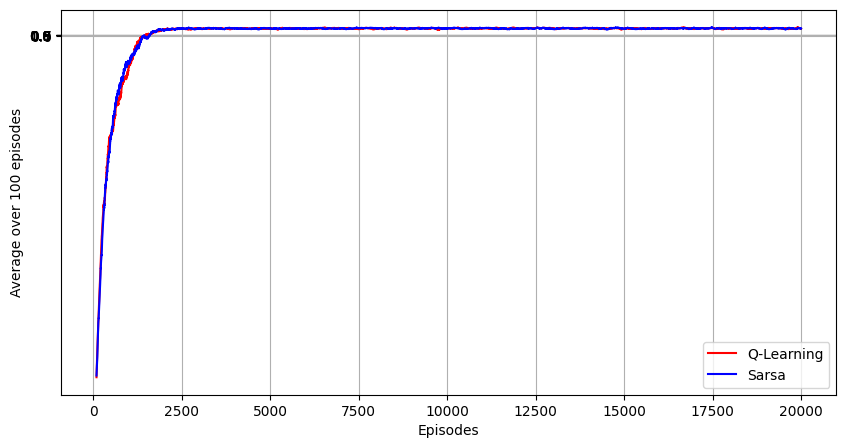

In [48]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(len(rewards_all)), average_y, color='red', label='Q-Learning')
plt.plot(np.arange(len(rewards_all_sarsa)), average_y_sarsa, color='blue', label='Sarsa')
plt.yticks([0, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
plt.grid()
plt.xlabel('Episodes')
plt.ylabel(f'Average over {window} episodes')
plt.legend()
plt.show()

# **KẾT LUẬN**


### So sánh hiệu quả giữa Q-learning và SARSA

Trong quá trình đánh giá hiệu quả của hai thuật toán **Q-learning** và **SARSA**, em dựa trên ba tiêu chí chính:

- **Tỉ lệ thành công trên 1000 tập kiểm tra**
- **Số bước di chuyển trung bình**
- **Thời gian thực thi**

#### 1. Kết quả tổng quan
- Cả hai thuật toán đều cho kết quả tương đương về **số bước trung bình** và **thời gian chạy**.
- Tuy nhiên, khi áp dụng trên môi trường **FrozenLake8x8**, bộ hyperparameters mặc định không mang lại hiệu quả tốt do **tốc độ hội tụ chậm**.

#### 2. Điều chỉnh hyperparameters
Để cải thiện quá trình huấn luyện trên FrozenLake8x8, em đã thực hiện các điều chỉnh sau:

- Tăng `num_steps_per_episode` lên **200**
- Giảm `decay_rate` xuống **0.00005**
- Giảm `min_epsilon` xuống **0.05**
- Tăng `num_episodes` lên **80.000**
Các thay đổi này giúp tăng tốc độ hội tụ và cải thiện hiệu suất huấn luyện đáng kể.

#### 3. Kết quả trên môi trường Taxi-v3
- Cả Q-learning và SARSA đều **hội tụ rất nhanh và đạt kết quả tối ưu**, cho thấy **Taxi-v3** là một môi trường khá đơn giản đối với cả hai thuật toán, đều cho tỉ lệ thắng là 100%

#### 4. So sánh hiệu quả giữa hai thuật toán
- **SARSA** cho kết quả tốt hơn về **tỉ lệ chiến thắng cuối cùng**.
- Tuy nhiên, **Q-learning** lại cho thấy **reward trung bình cao hơn ở giai đoạn đầu huấn luyện**



> Nhìn chung, việc lựa chọn giữa Q-learning và SARSA có thể phụ thuộc vào mục tiêu cụ thể: nếu quan tâm đến hiệu quả ban đầu, Q-learning có thể là lựa chọn tốt; còn nếu cần sự ổn định và tỉ lệ thành công cao hơn sau quá trình huấn luyện dài, SARSA có thể phù hợp hơn.

